In [1]:
import numpy as np
import scipy.io as sio
import scipy.signal as signal
import matplotlib.pyplot as plt

# **Setup & Channel-to-Region Mapping**

In [2]:
# The 19 standard channels in the ADHD dataset layout
CHANNELS = ['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 
            'F7', 'F8', 'T3', 'T4', 'T5', 'T6', 'Fz', 'Cz', 'Pz']


In [3]:
# 5 Scalp Regions mapping
REGIONS = {
    'Frontal':   ['Fp1', 'Fp2', 'F3', 'F4', 'F7', 'F8', 'Fz'],
    'Temporal':  ['T3', 'T4', 'T5', 'T6'],
    'Central':   ['C3', 'C4', 'Cz'],
    'Parietal':  ['P3', 'P4', 'Pz'],
    'Occipital': ['O1', 'O2']
}

# Synthetic Data Generator

In [4]:
def generate_synthetic_adhd_eeg(duration_sec=10, fs=128, is_adhd=False):
    """
    Generates synthetic 19-channel EEG data.
    If is_adhd=True, injects higher Theta wave (4-8 Hz) power in Frontal/Central channels.
    """
    t = np.linspace(0, duration_sec, int(fs * duration_sec))
    num_channels = len(CHANNELS)
    eeg_matrix = np.zeros((num_channels, len(t)))
    
    np.random.seed(42 if is_adhd else 101)
    
    for idx, ch in enumerate(CHANNELS):
        # Base rhythms (Alpha: 8-12 Hz, Beta: 13-30 Hz) + Noise
        alpha = 0.5 * np.sin(2 * np.pi * 10 * t)
        beta  = 0.3 * np.sin(2 * np.pi * 20 * t)
        noise = 0.4 * np.random.randn(len(t))
        
        # ADHD hallmark: Elevated Theta band (4-8 Hz) in Frontal/Central channels
        if is_adhd and ch in REGIONS['Frontal'] + REGIONS['Central']:
            theta = 1.8 * np.sin(2 * np.pi * 6 * t) # High theta
        else:
            theta = 0.4 * np.sin(2 * np.pi * 6 * t) # Normal theta
            
        eeg_matrix[idx, :] = alpha + beta + theta + noise
        
    return eeg_matrix, t

In [5]:
def load_adhd_kaggle_csv(csv_path='/kaggle/input/datasets/mouadelbaz/eeg-dataset-for-adhd/adhdata.csv'):
    """
    Loads the Kaggle CSV file and converts flattened rows back into 
    subject-level 2D matrices of shape (19, Total_Time_Steps).
    """
    print(f"Loading CSV from {csv_path}...")
    df = pd.read_csv(csv_path)
    
    # Standardize column names (lowercase & stripped)
    df.columns = df.columns.str.strip()
    
    # Identify subject and label column names dynamically
    subject_col = [c for c in df.columns if 'subject' in c.lower() or 'patient' in c.lower() or 'id' in c.lower()][0]
    label_col   = [c for c in df.columns if 'class' in c.lower() or 'label' in c.lower() or 'target' in c.lower() or 'adhd' in c.lower()][0]
    
    subjects_data = []
    labels = []
    
    # Group continuous rows by individual subject ID
    for sub_id, group in df.groupby(subject_col):
        # Extract 19 channel columns as a 2D matrix (Time_Steps, 19)
        eeg_raw = group[CHANNELS].values
        
        # Transpose to match standard EEG shape: (19, Time_Steps)
        eeg_matrix = eeg_raw.T
        
        # Extract label (0 = Control, 1 = ADHD)
        sub_label = group[label_col].iloc[0]
        
        subjects_data.append(eeg_matrix)
        labels.append(sub_label)
        
    print(f"Loaded {len(subjects_data)} subjects successfully.")
    return subjects_data, np.array(labels)

# Signal Filtering & 19-Channel Multichannel Plot

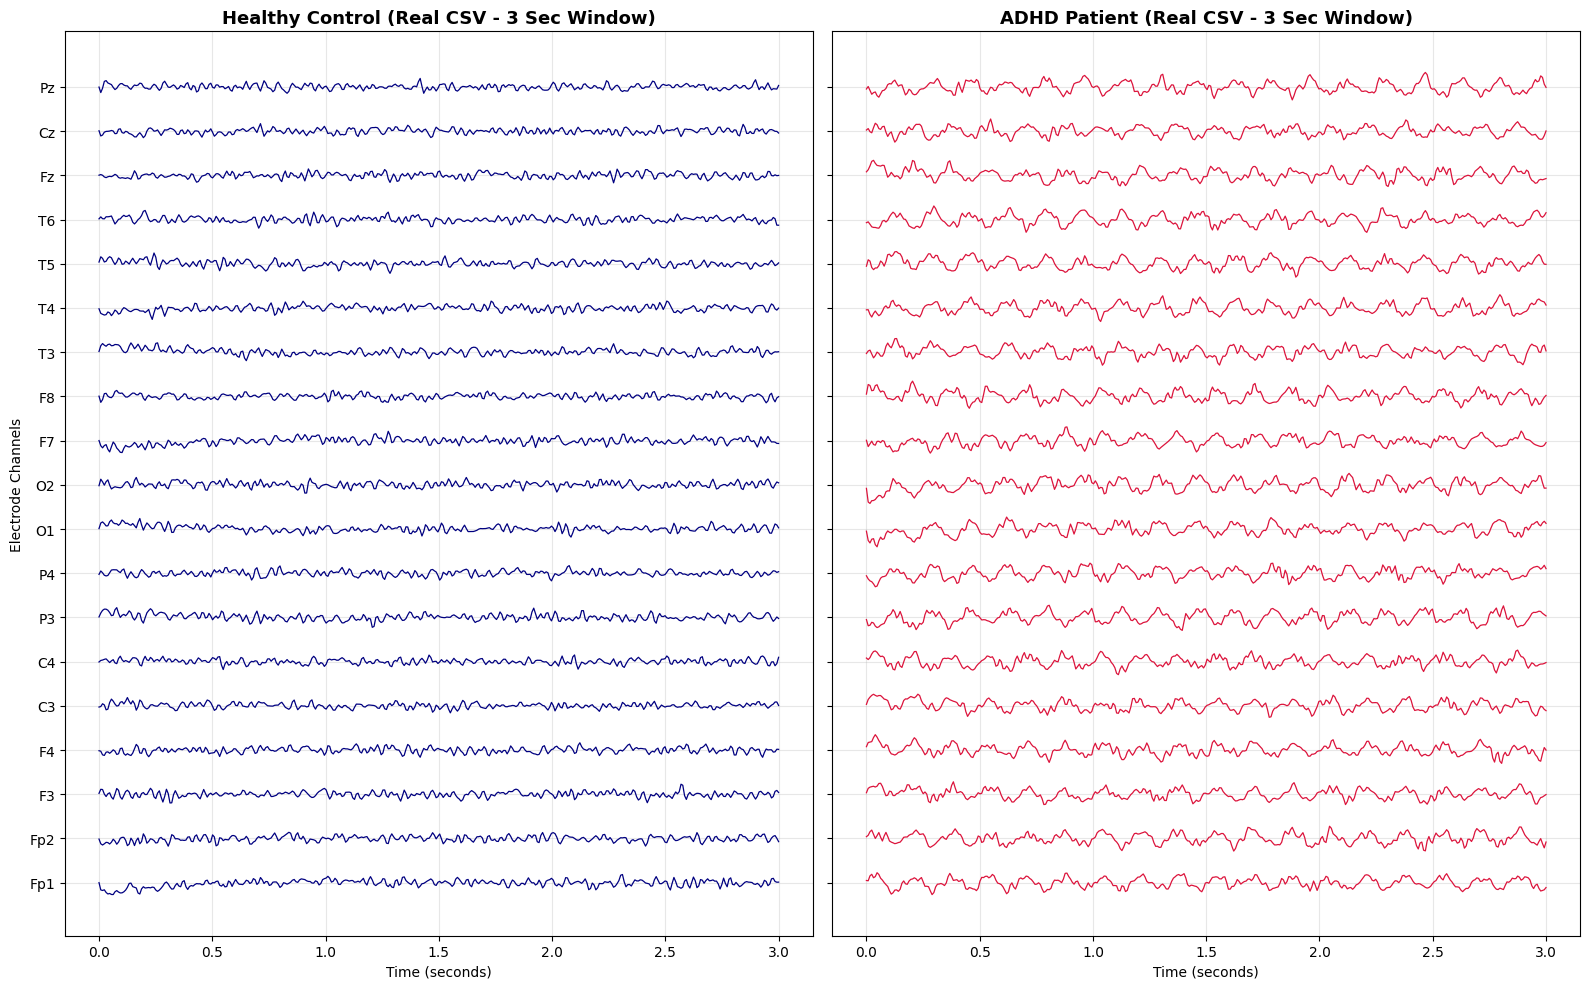

In [8]:
def preprocess_numpy(eeg_matrix, fs=128):
    """
    Applies 0.5-40 Hz Butterworth Bandpass filter + Common Average Reference (CAR)
    """
    # 1. Bandpass filter
    nyq = 0.5 * fs
    b, a = signal.butter(4, [0.5 / nyq, 40.0 / nyq], btype='band')
    filtered = signal.filtfilt(b, a, eeg_matrix, axis=-1)
    
    # 2. CAR (Subtract channel mean per time step)
    car_eeg = filtered - np.mean(filtered, axis=0, keepdims=True)
    return car_eeg

# Generate Control and ADHD EEG samples
eeg_control, t = generate_synthetic_adhd_eeg(is_adhd=False)
eeg_adhd, _    = generate_synthetic_adhd_eeg(is_adhd=True)

# Preprocess real raw signals loaded from Kaggle CSV
clean_control = preprocess_numpy(eeg_control)
clean_adhd    = preprocess_numpy(eeg_adhd)

# Time axis parameters (3-second snippet at fs=128 Hz)
fs = 128
sample_pts = int(fs * 3)  # 384 samples
t = np.linspace(0, 3.0, sample_pts)

# Plot 19-Channel Continuous Signal Comparison (First 3 seconds)
fig, axes = plt.subplots(1, 2, figsize=(16, 10), sharey=True)

# -------------------------------------------------------------
# FIXED OFFSET: Dynamically scale or set to 5.0 to reveal waves
# -------------------------------------------------------------
CHANNEL_OFFSET = 5.0  # Reduced from 100.0 to match real signal scale

for idx, ch in enumerate(CHANNELS):
    offset = idx * CHANNEL_OFFSET
    axes[0].plot(t, clean_control[idx, :sample_pts] + offset, color='navy', lw=0.9)
    axes[1].plot(t, clean_adhd[idx, :sample_pts] + offset, color='crimson', lw=0.9)

axes[0].set_yticks([i * CHANNEL_OFFSET for i in range(len(CHANNELS))])
axes[0].set_yticklabels(CHANNELS)
axes[0].set_title("Healthy Control (Real CSV - 3 Sec Window)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Electrode Channels")
axes[0].grid(True, alpha=0.3)

axes[1].set_title("ADHD Patient (Real CSV - 3 Sec Window)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Time (seconds)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Power Spectral Density (PSD) Analysis Across 5 Regions

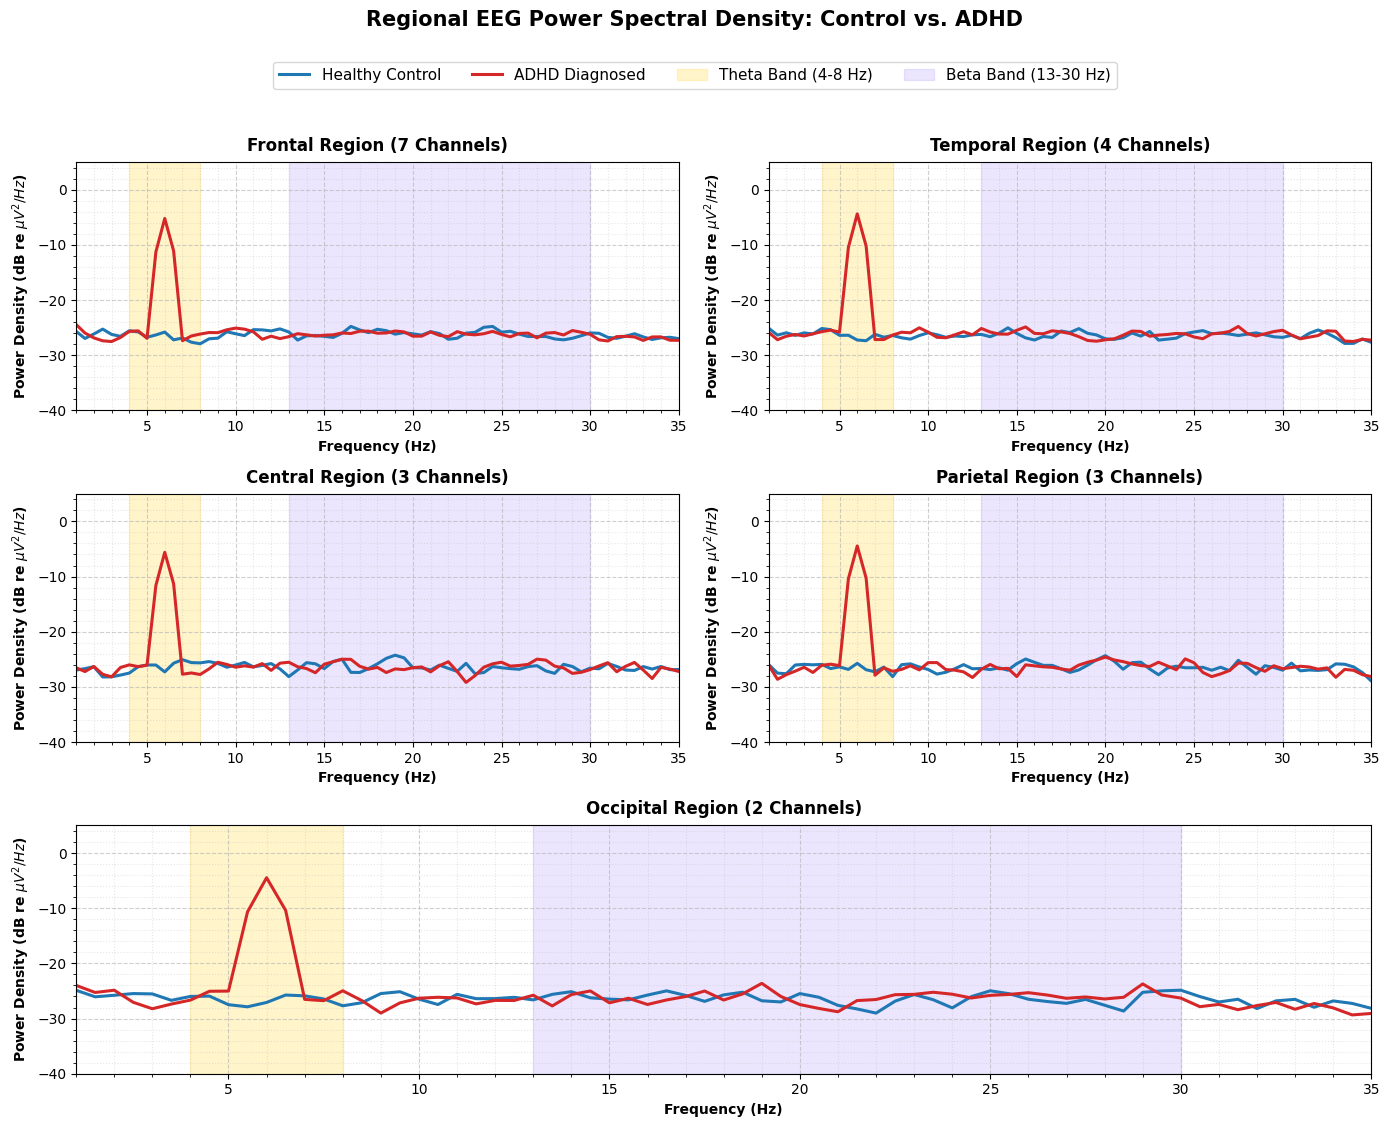

In [11]:
def plot_regional_psd_2x2(control_data, adhd_data, fs=128):
    """
    Plots regional PSD in a 2x2 grid (Frontal, Temporal, Central, Parietal)
    with the 5th region (Occipital) spanning the full bottom row.
    """
    fig = plt.figure(figsize=(14, 11))
    
    # Define 2x2 grid for top four regions + bottom span for 5th region
    axes = [
        plt.subplot2grid((3, 2), (0, 0)), # Frontal (Top-Left)
        plt.subplot2grid((3, 2), (0, 1)), # Temporal (Top-Right)
        plt.subplot2grid((3, 2), (1, 0)), # Central (Mid-Left)
        plt.subplot2grid((3, 2), (1, 1)), # Parietal (Mid-Right)
        plt.subplot2grid((3, 2), (2, 0), colspan=2) # Occipital (Bottom Spanning Both Columns)
    ]
    
    legend_handles = {}

    for r_idx, (region_name, ch_list) in enumerate(REGIONS.items()):
        ch_indices = [CHANNELS.index(ch) for ch in ch_list]
        
        # 1. Welch PSD calculation (0.5 Hz resolution)
        f, psd_ctrl = signal.welch(control_data[ch_indices, :], fs=fs, nperseg=2*fs, axis=-1)
        mean_psd_ctrl = np.mean(psd_ctrl, axis=0)
        
        _, psd_adhd = signal.welch(adhd_data[ch_indices, :], fs=fs, nperseg=2*fs, axis=-1)
        mean_psd_adhd = np.mean(psd_adhd, axis=0)
        
        # 2. Log Conversion to dB
        db_ctrl = 10 * np.log10(mean_psd_ctrl + 1e-12)
        db_adhd = 10 * np.log10(mean_psd_adhd + 1e-12)
        
        ax = axes[r_idx]
        
        # Plot traces
        l1, = ax.plot(f, db_ctrl, label='Healthy Control', color='#1f77b4', lw=2.2)
        l2, = ax.plot(f, db_adhd, label='ADHD Diagnosed', color='#d62728', lw=2.2)
        
        # Highlight bands
        v1 = ax.axvspan(4, 8, color='#ffe169', alpha=0.35, label='Theta Band (4–8 Hz)')
        v2 = ax.axvspan(13, 30, color='#b19ffb', alpha=0.25, label='Beta Band (13–30 Hz)')
        
        if r_idx == 0:
            legend_handles = {'Healthy Control': l1, 'ADHD Diagnosed': l2, 'Theta Band (4-8 Hz)': v1, 'Beta Band (13-30 Hz)': v2}

        # Styling
        ax.set_xlim(1, 35)
        ax.set_ylim(-40, 5)
        ax.set_title(f"{region_name} Region ({len(ch_list)} Channels)", fontweight='bold', fontsize=12, pad=8)
        ax.set_xlabel("Frequency (Hz)", fontsize=10, fontweight='semibold')
        ax.set_ylabel(r"Power Density (dB re $\mu V^2/Hz$)", fontsize=10, fontweight='semibold')
        
        ax.grid(True, which='major', linestyle='--', alpha=0.6)
        ax.minorticks_on()
        ax.grid(True, which='minor', linestyle=':', alpha=0.3)

    # Consolidated Top Legend
    fig.legend(
        handles=list(legend_handles.values()),
        labels=list(legend_handles.keys()),
        loc='upper center',
        bbox_to_anchor=(0.5, 0.98),
        ncol=4,
        frameon=True,
        fontsize=11
    )

    plt.suptitle("Regional EEG Power Spectral Density: Control vs. ADHD", fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

# Run the updated 2x2 + bottom-span plotter
plot_regional_psd_2x2(clean_control[:, :1280], clean_adhd[:, :1280])